In [49]:
print("********DATA LOADING & UNDERSTANDING********")

import pandas as pd
import numpy as np

# LOAD THE SELECTED DATASET USING PANDAS

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("energy-data.csv")

print("******** DATASET LOADED SUCCESSFULLY **********")
print(df)

********DATA LOADING & UNDERSTANDING********


Saving energy-data.csv to energy-data (1).csv
******** DATASET LOADED SUCCESSFULLY **********
             country  year iso_code  population           gdp  \
0      ASEAN (Ember)  2000      NaN         NaN           NaN   
1      ASEAN (Ember)  2001      NaN         NaN           NaN   
2      ASEAN (Ember)  2002      NaN         NaN           NaN   
3      ASEAN (Ember)  2003      NaN         NaN           NaN   
4      ASEAN (Ember)  2004      NaN         NaN           NaN   
...              ...   ...      ...         ...           ...   
23227       Zimbabwe  2020      ZWE  15526887.0  2.317871e+10   
23228       Zimbabwe  2021      ZWE  15797220.0  2.514009e+10   
23229       Zimbabwe  2022      ZWE  16069061.0  2.590159e+10   
23230       Zimbabwe  2023      ZWE  16340829.0           NaN   
23231       Zimbabwe  2024      ZWE  16634366.0           NaN   

       biofuel_cons_change_pct  biofuel_cons_change_twh  \
0                          NaN                      NaN   
1      

In [50]:
# INSPECT THE FIRST AND LAST ROWS

print("\n***** FIRST 5 ROWS *****")
print(df.head())

print("\n***** LAST 5 ROWS *****")
print(df.tail())


# IDENTIFY ROWS AND COLUMNS

print("\n***** DATASET DIMENSIONS *****")

rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)
print("Dataset Shape:", df.shape)


# CHECK COLUMN NAMES AND DATA TYPES

print("\n***** COLUMN NAMES *****")
print(df.columns.tolist())

print("\n***** DATA TYPES *****")
print(df.dtypes)

print("\n***** DATASET INFORMATION *****")
df.info()


# GENERATE DESCRIPTIVE STATISTICS

print("\n***** NUMERICAL DESCRIPTIVE STATISTICS *****")
print(df.describe())

print("\n***** CATEGORICAL DESCRIPTIVE STATISTICS *****")
print(df.describe(include="object"))

print("\n***** COMPLETE DESCRIPTIVE STATISTICS *****")
print(df.describe(include="all"))


# IDENTIFY NUMERICAL AND CATEGORICAL VARIABLES

print("\n***** NUMERICAL VARIABLES *****")

numerical_variables = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Variables:")
print(numerical_variables)

print("\n***** CATEGORICAL VARIABLES *****")

categorical_variables = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical Variables:")
print(categorical_variables)

print("\nTotal Numerical Variables:", len(numerical_variables))
print("Total Categorical Variables:", len(categorical_variables))


# CHECK UNIQUE VALUES AND TIME COVERAGE

print("\n***** UNIQUE VALUES *****")

for column in df.columns:
    print(f"\nColumn: {column}")
    print("Number of Unique Values:", df[column].nunique())
    print("Unique Values:")
    print(df[column].unique())

# Check unique values for each column
print("\n***** UNIQUE VALUE COUNTS *****")

for column in df.columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


# TIME COVERAGE ANALYSIS

print("\n***** TIME COVERAGE ANALYSIS *****")

# Identify possible date/time columns
datetime_columns = []

for column in df.columns:
    if "date" in column.lower() or "time" in column.lower():
        datetime_columns.append(column)

if len(datetime_columns) > 0:

    for column in datetime_columns:

        df[column] = pd.to_datetime(
            df[column],
            errors="coerce"
        )

        print(f"\nTime Column: {column}")
        print("Earliest Date:", df[column].min())
        print("Latest Date:", df[column].max())
        print("Total Valid Dates:", df[column].count())
        print("Unique Dates:", df[column].nunique())

else:
    print("No date/time columns found in the dataset.")
    print("Time coverage analysis is not applicable.")




***** FIRST 5 ROWS *****
         country  year iso_code  population  gdp  biofuel_cons_change_pct  \
0  ASEAN (Ember)  2000      NaN         NaN  NaN                      NaN   
1  ASEAN (Ember)  2001      NaN         NaN  NaN                      NaN   
2  ASEAN (Ember)  2002      NaN         NaN  NaN                      NaN   
3  ASEAN (Ember)  2003      NaN         NaN  NaN                      NaN   
4  ASEAN (Ember)  2004      NaN         NaN  NaN                      NaN   

   biofuel_cons_change_twh  biofuel_cons_per_capita  biofuel_consumption  \
0                      NaN                      NaN                  NaN   
1                      NaN                      NaN                  NaN   
2                      NaN                      NaN                  NaN   
3                      NaN                      NaN                  NaN   
4                      NaN                      NaN                  NaN   

   biofuel_elec_per_capita  ...  solar_share_elec  sol

## 2. Data Validation and Cleaning

In this stage, I checked the dataset for missing values, duplicate records, inconsistent formats, and potential outliers. Based on the findings, I performed necessary cleaning while keeping the original information as much as possible.

In [51]:


import pandas as pd
import numpy as np

# Check whether the dataset is available
if "df" not in globals():
    raise NameError("Please run Member 1's data loading code first.")

print("\n========== DATA VALIDATION & CLEANING ==========")


# 1. CHECK MISSING VALUES

print("\n***** MISSING VALUE ANALYSIS *****")

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

print(missing_report)

print("\nTotal Missing Values:", df.isnull().sum().sum())


# 2. CHECK DUPLICATE RECORDS

print("\n***** DUPLICATE RECORD ANALYSIS *****")

duplicate_rows = df.duplicated().sum()

duplicate_country_year = df.duplicated(
    subset=["country", "year"]
).sum()

print("Complete Duplicate Rows:", duplicate_rows)
print("Duplicate Country-Year Records:", duplicate_country_year)


# 3. CHECK INCONSISTENT FORMATS

print("\n***** FORMAT CHECKING *****")

# Check unnecessary spaces in text columns

text_columns = df.select_dtypes(include=["object"]).columns

for column in text_columns:

    extra_spaces = (
        df[column].notna() &
        (df[column] != df[column].str.strip())
    ).sum()

    print(column, "- Extra Spaces:", extra_spaces)


# Check year format

print("\nYear Data Type:", df["year"].dtype)
print("Earliest Year:", df["year"].min())
print("Latest Year:", df["year"].max())


# Check numerical data types

print("\nNumerical Data Types:")
print(df.select_dtypes(include=np.number).dtypes.value_counts())


# 4. IDENTIFY POTENTIAL OUTLIERS

print("\n***** OUTLIER DETECTION USING IQR *****")

numeric_columns = df.select_dtypes(include=np.number).columns

outlier_results = []

for column in numeric_columns:

    if column == "year":
        continue

    values = df[column].dropna()

    if values.empty:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (values < lower_limit) |
        (values > upper_limit)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Outlier Count": outlier_count
    })

outlier_report = pd.DataFrame(outlier_results)

print(
    outlier_report.sort_values(
        by="Outlier Count",
        ascending=False
    ).head(20).to_string(index=False)
)


# 5. CREATE A CLEANED COPY

print("\n***** DATA CLEANING *****")

df_clean = df.copy()

# Remove unnecessary spaces from text columns

for column in text_columns:

    df_clean[column] = df_clean[column].str.strip()

print("Text formatting completed.")

# Keep missing values unchanged
# They will not be replaced without proper justification

print("Missing values preserved:",
      df_clean.isnull().sum().sum())


# 6. REMOVE EXACT DUPLICATES

print("\n***** DUPLICATE REMOVAL *****")

rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates()

rows_after = len(df_clean)

print("Rows Before Cleaning:", rows_before)
print("Rows After Cleaning:", rows_after)
print("Rows Removed:", rows_before - rows_after)


# 7. DOCUMENT CLEANING DECISIONS

print("\n***** CLEANING DECISIONS *****")

cleaning_decisions = pd.DataFrame({
    "Data Issue": [
        "Missing Values",
        "Duplicate Records",
        "Inconsistent Formats",
        "Potential Outliers"
    ],

    "Action Taken": [
        "Kept missing values unchanged",
        "Removed exact duplicate rows",
        "Removed unnecessary spaces",
        "Identified and retained for further investigation"
    ]
})

print(cleaning_decisions.to_string(index=False))


# 8. FINAL DATA VALIDATION

print("\n***** FINAL DATA VALIDATION *****")

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("Remaining Missing Values:",
      df_clean.isnull().sum().sum())

print("Remaining Duplicate Rows:",
      df_clean.duplicated().sum())

print("\nCleaned Dataset Preview:")

print(df_clean.head())


# 9. SAVE THE CLEANED DATASET

df_clean.to_csv("energy-data_cleaned.csv", index=False)

print("\n========== CLEANING COMPLETED ==========")

print("Cleaned dataset saved as: energy-data_cleaned.csv")



========== DATA VALIDATION & CLEANING ==========

***** MISSING VALUE ANALYSIS *****
                                  Missing Values  Missing Percentage
biofuel_cons_change_pct                    21162               91.09
solar_cons_change_pct                      20717               89.17
nuclear_cons_change_pct                    20653               88.90
wind_cons_change_pct                       20434               87.96
other_renewables_cons_change_pct           19244               82.83
...                                          ...                 ...
iso_code                                    6098               26.25
gas_production                              5981               25.74
oil_prod_change_twh                         5503               23.69
oil_production                              5240               22.56
population                                  4472               19.25

[128 rows x 2 columns]

Total Missing Values: 1988709

***** DUPLICATE RECORD ANALYSI

3. Statistical Analysis and Exploratory Data Analysis (EDA)
In this section, I perform a numerical investigation of the global energy dataset. The analysis focuses on descriptive statistics, country-wise and year-wise comparisons, distributions, trends, correlation analysis, and research questions.

The original dataset is retained. For country-level comparisons, records with a valid iso_code are used to avoid mixing individual countries with aggregate regions such as World, Africa, and Asia. The World aggregate is used separately for global trend analysis.

In [52]:
# STATISTICAL ANALYSIS & EDA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the cleaned dataset from Member 2 when available
if "df_clean" in globals():
    analysis_df = df_clean.copy()
else:
    analysis_df = df.copy()

# Separate country-level observations from aggregate entities
country_data = analysis_df[analysis_df["iso_code"].notna()].copy()
world_data = analysis_df[analysis_df["country"].eq("World")].copy()

print("========== STATISTICAL ANALYSIS & EDA ==========")
print("Total dataset records:", len(analysis_df))
print("Country-level records:", len(country_data))
print("Number of countries:", country_data["iso_code"].nunique())
print("Year range:", analysis_df["year"].min(), "to", analysis_df["year"].max())


========== STATISTICAL ANALYSIS & EDA ==========
Total dataset records: 23232
Country-level records: 17134
Number of countries: 220
Year range: 1900 to 2025


In [53]:
# DESCRIPTIVE STATISTICS

selected_variables = [
    "population",
    "gdp",
    "primary_energy_consumption",
    "energy_per_capita",
    "electricity_generation",
    "fossil_fuel_consumption",
    "renewables_consumption",
    "renewables_share_energy",
    "greenhouse_gas_emissions",
    "carbon_intensity_elec"
]

available_variables = [
    col for col in selected_variables if col in country_data.columns
]

descriptive_stats = country_data[available_variables].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

descriptive_stats = descriptive_stats.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "median": "Median",
    "std": "Standard Deviation",
    "min": "Minimum",
    "max": "Maximum"
})

print("***** DESCRIPTIVE STATISTICS FOR COUNTRY RECORDS *****")
display(descriptive_stats.round(2))


***** DESCRIPTIVE STATISTICS FOR COUNTRY RECORDS *****


,Count,Mean,Median,Standard Deviation,Minimum,Maximum
population,16981.0,2.712684e+07,5.636206e+06,1.025765e+08,1776.0,1.450936e+09
gdp,11559.0,3.175613e+11,4.228729e+10,1.238160e+12,164206000.0,2.696602e+13
primary_energy_consumption,10355.0,5.895900e+02,4.017000e+01,2.553260e+03,0.0,4.898710e+04
energy_per_capita,10298.0,2.582679e+04,1.194036e+04,3.930790e+04,0.0,6.518366e+05
electricity_generation,6375.0,1.168100e+02,1.288000e+01,4.912800e+02,0.0,1.008688e+04
fossil_fuel_consumption,4465.0,1.152610e+03,2.806600e+02,3.275310e+03,0.0,3.890727e+04
renewables_consumption,4465.0,1.117900e+02,1.749000e+01,3.674900e+02,0.0,8.470080e+03
renewables_share_energy,4459.0,1.050000e+01,5.100000e+00,1.386000e+01,0.0,8.613000e+01
greenhouse_gas_emissions,5150.0,5.700000e+01,2.060000e+00,3.050500e+02,0.0,5.602240e+03
carbon_intensity_elec,5492.0,4.736900e+02,5.238100e+02,2.483100e+02,0.0,1.306720e+03


***** TOP 10 COUNTRIES BY PRIMARY ENERGY CONSUMPTION (2023) *****


,country,primary_energy_consumption
4574,China,47072.01
21856,United States,26216.54
9632,India,10827.86
18042,Russia,8760.90
10553,Japan,4858.53
3911,Canada,3887.86
3094,Brazil,3853.75
9882,Iran,3596.10
19321,South Korea,3557.90
18519,Saudi Arabia,3200.74


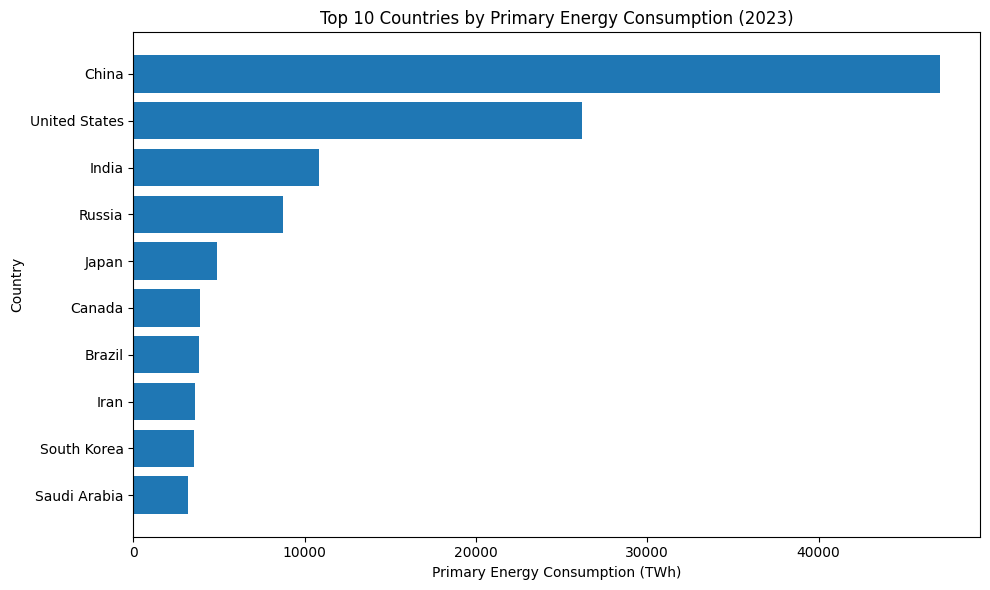

In [54]:
# COUNTRY-WISE COMPARISON FOR 2023

comparison_year = 2023
country_year_data = country_data[country_data["year"] == comparison_year].copy()

if "primary_energy_consumption" in country_year_data.columns:
    top_energy_countries = (
        country_year_data[["country", "primary_energy_consumption"]]
        .dropna()
        .sort_values("primary_energy_consumption", ascending=False)
        .head(10)
    )

    print(f"***** TOP 10 COUNTRIES BY PRIMARY ENERGY CONSUMPTION ({comparison_year}) *****")
    display(top_energy_countries.round(2))

    plt.figure(figsize=(10, 6))
    plt.barh(
        top_energy_countries["country"][::-1],
        top_energy_countries["primary_energy_consumption"][::-1]
    )
    plt.xlabel("Primary Energy Consumption (TWh)")
    plt.ylabel("Country")
    plt.title(f"Top 10 Countries by Primary Energy Consumption ({comparison_year})")
    plt.tight_layout()
    plt.show()


***** WORLD YEAR-WISE ENERGY INDICATORS *****


,year,primary_energy_consumption,electricity_generation,fossil_fuel_consumption,renewables_consumption,greenhouse_gas_emissions
22830,2010,141602.05,21263.61,121801.43,11784.37,11564.29
22831,2011,144913.30,21971.91,124911.51,12318.80,12089.34
22832,2012,147002.42,22515.71,126707.33,13101.09,12341.73
22833,2013,149599.73,23155.24,128401.55,13929.00,12697.37
22834,2014,151239.17,23747.12,129225.12,14629.96,12935.75
22835,2015,152357.62,24003.19,129769.42,15143.94,12802.65
22836,2016,154221.48,24695.32,130666.33,15981.75,12972.36
22837,2017,157625.31,25441.97,133092.72,16900.69,13281.54
22838,2018,161806.12,26465.29,136007.17,18004.24,13722.26
22839,2019,163694.61,26840.51,136678.06,18936.26,13571.12


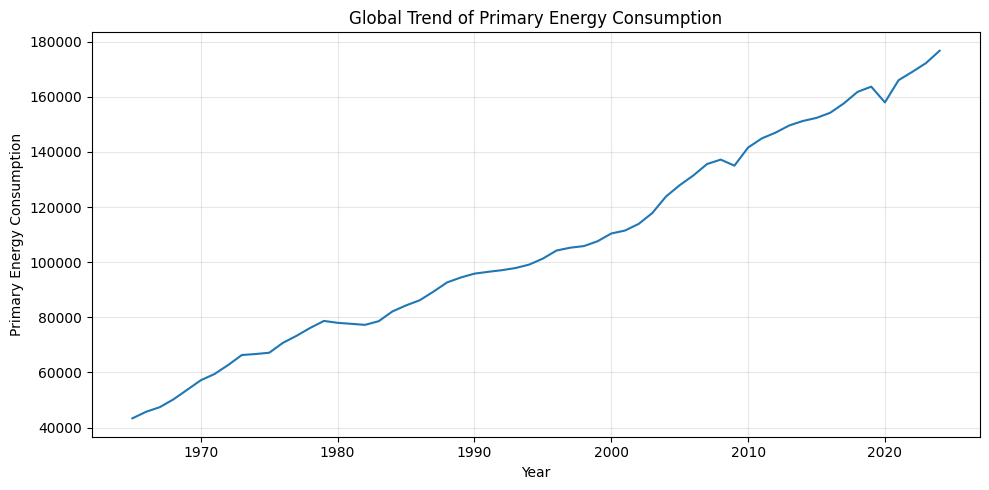

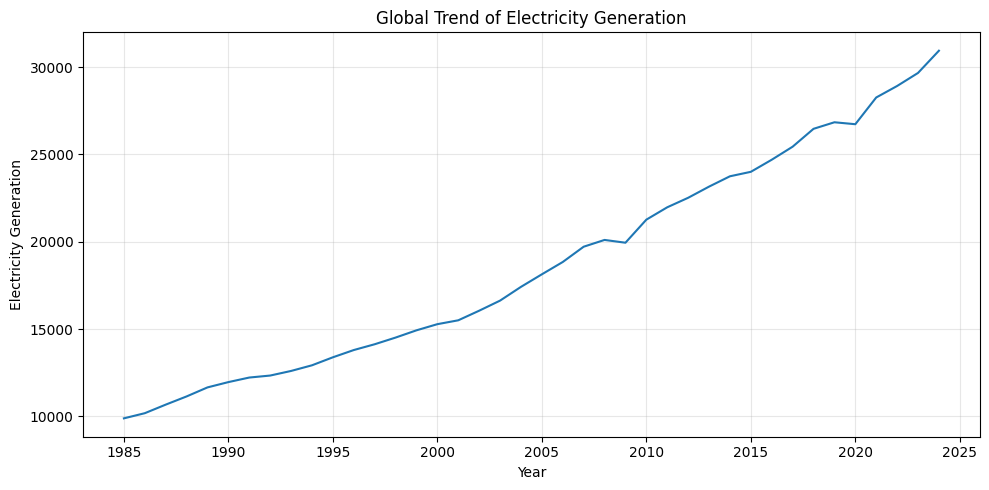

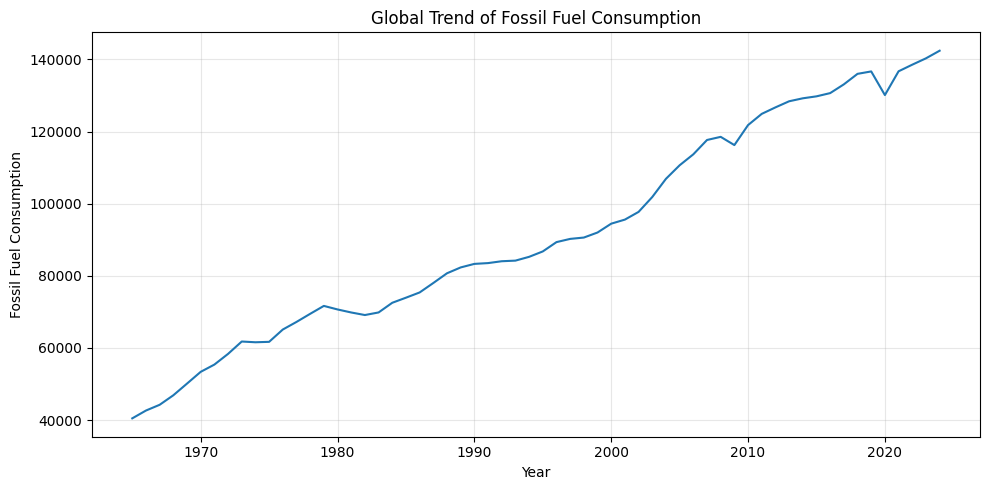

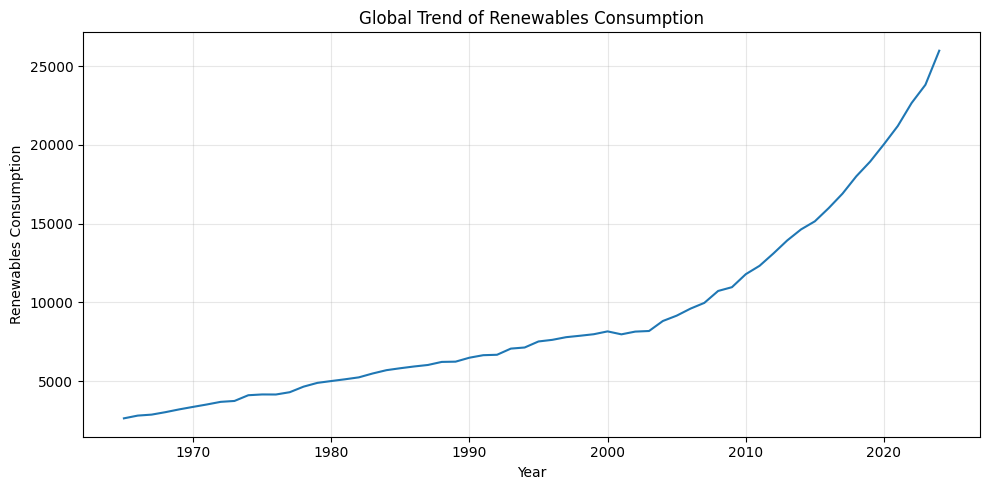

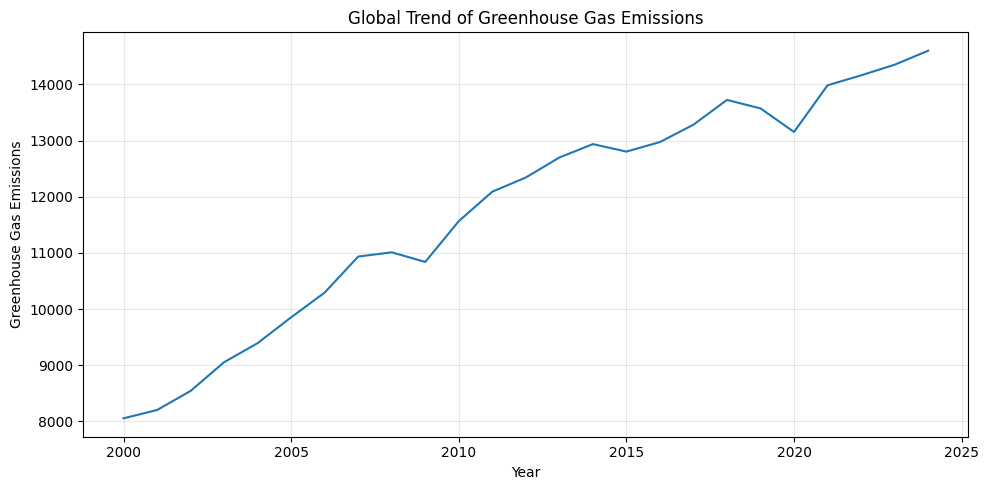

***** GLOBAL COMPARISON: 2000 VS 2024 *****


year,2000,2024
primary_energy_consumption,110416.40,176737.09
electricity_generation,15278.69,30938.18
fossil_fuel_consumption,94467.26,142420.89
renewables_consumption,8152.47,25979.02
greenhouse_gas_emissions,8055.74,14597.91


In [55]:
# GLOBAL TREND ANALYSIS USING THE WORLD AGGREGATE

trend_variables = [
    "primary_energy_consumption",
    "electricity_generation",
    "fossil_fuel_consumption",
    "renewables_consumption",
    "greenhouse_gas_emissions"
]

available_trend_variables =[
    col for col in trend_variables if col in world_data.columns
]

world_yearly =(
    world_data[["year"] + available_trend_variables]
    .sort_values("year")
    .drop_duplicates(subset="year")
)

print("***** WORLD YEAR-WISE ENERGY INDICATORS *****")
display(world_yearly.tail(15).round(2))

for variable in available_trend_variables:
    plt.figure(figsize=(10, 5))
    plt.plot(world_yearly["year"], world_yearly[variable])
    plt.xlabel("Year")
    plt.ylabel(variable.replace("_", " ").title())
    plt.title(f"Global Trend of {variable.replace('_', ' ').title()}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Compare 2000 and 2024 where both observations exist
comparison_years = world_yearly[world_yearly["year"].isin([2000, 2024])]
print("***** GLOBAL COMPARISON: 2000 VS 2024 *****")
display(comparison_years.set_index("year").T.round(2))


Observations: 10355
Skewness: 9.934


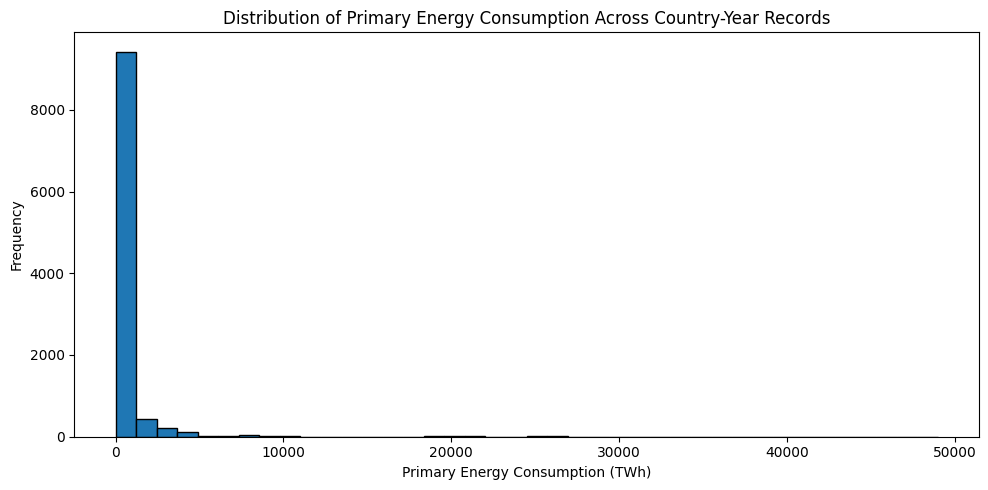

In [56]:
# DISTRIBUTION OF PRIMARY ENERGY CONSUMPTION

if "primary_energy_consumption" in country_data.columns:
    energy_values = country_data["primary_energy_consumption"].dropna()

    print("Observations:", len(energy_values))
    print("Skewness:", round(energy_values.skew(), 3))

    plt.figure(figsize=(10, 5))
    plt.hist(energy_values, bins=40, edgecolor="black")
    plt.xlabel("Primary Energy Consumption (TWh)")
    plt.ylabel("Frequency")
    plt.title("Distribution of Primary Energy Consumption Across Country-Year Records")
    plt.tight_layout()
    plt.show()


***** PEARSON CORRELATION MATRIX (2022) *****


,population,gdp,primary_energy_consumption,electricity_generation,fossil_fuel_consumption,renewables_consumption,greenhouse_gas_emissions,renewables_share_energy,carbon_intensity_elec
population,1.00,0.82,0.78,0.79,0.78,0.75,0.83,-0.06,0.06
gdp,0.82,1.00,0.98,0.97,0.98,0.93,0.94,-0.05,0.08
primary_energy_consumption,0.78,0.98,1.00,0.99,1.00,0.96,0.97,-0.05,0.05
electricity_generation,0.79,0.97,0.99,1.00,0.99,0.97,0.99,-0.03,0.04
fossil_fuel_consumption,0.78,0.98,1.00,0.99,1.00,0.95,0.97,-0.08,0.12
renewables_consumption,0.75,0.93,0.96,0.97,0.95,1.00,0.95,0.09,-0.02
greenhouse_gas_emissions,0.83,0.94,0.97,0.99,0.97,0.95,1.00,-0.07,0.08
renewables_share_energy,-0.06,-0.05,-0.05,-0.03,-0.08,0.09,-0.07,1.00,-0.70
carbon_intensity_elec,0.06,0.08,0.05,0.04,0.12,-0.02,0.08,-0.70,1.00


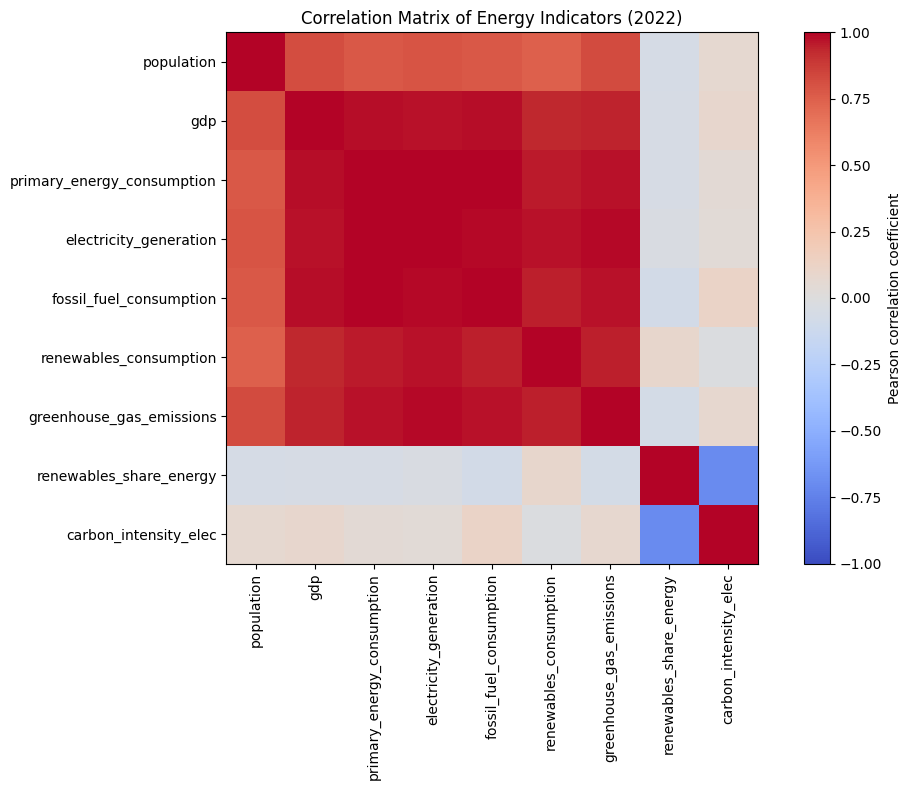

***** SELECTED CORRELATION RESULTS *****


,Variable 1,Variable 2,Valid observations,Pearson correlation
0,population,primary_energy_consumption,216,0.780
1,gdp,primary_energy_consumption,165,0.982
2,electricity_generation,greenhouse_gas_emissions,213,0.987
3,fossil_fuel_consumption,greenhouse_gas_emissions,79,0.973
4,renewables_share_energy,carbon_intensity_elec,79,-0.700


In [57]:
# CORRELATION ANALYSIS FOR COUNTRY-LEVEL RECORDS IN 2022

correlation_variables =[
    "population",
    "gdp",
    "primary_energy_consumption",
    "electricity_generation",
    "fossil_fuel_consumption",
    "renewables_consumption",
    "greenhouse_gas_emissions",
    "renewables_share_energy",
    "carbon_intensity_elec"
]

available_corr_variables = [
    col for col in correlation_variables if col in country_data.columns
]

data_2022 = country_data[country_data["year"] == 2022].copy()
correlation_matrix = data_2022[available_corr_variables].corr(method="pearson")

print("***** PEARSON CORRELATION MATRIX (2022) *****")
display(correlation_matrix.round(2))

plt.figure(figsize=(11, 8))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation coefficient")
plt.xticks(
    range(len(available_corr_variables)),
    available_corr_variables,
    rotation=90
)
plt.yticks(range(len(available_corr_variables)), available_corr_variables)
plt.title("Correlation Matrix of Energy Indicators (2022)")
plt.tight_layout()
plt.show()

# Report pairwise correlation values and their valid sample sizes
correlation_pairs = [
    ("population", "primary_energy_consumption"),
    ("gdp", "primary_energy_consumption"),
    ("electricity_generation", "greenhouse_gas_emissions"),
    ("fossil_fuel_consumption", "greenhouse_gas_emissions"),
    ("renewables_share_energy", "carbon_intensity_elec")
]

pair_results = []

for x, y in correlation_pairs:
    if x in data_2022.columns and y in data_2022.columns:
        pair_data = data_2022[[x, y]].dropna()
        pair_results.append({
            "Variable 1": x,
            "Variable 2": y,
            "Valid observations": len(pair_data),
            "Pearson correlation": pair_data[x].corr(pair_data[y])
        })

pair_correlation_report = pd.DataFrame(pair_results)
print("***** SELECTED CORRELATION RESULTS *****")
display(pair_correlation_report.round(3))


4.Data Visualization and Graphical Investigation
This section presents visual analysis of global energy data. It includes energy-consumption trends, country comparisons, renewable versus fossil-fuel comparisons, numerical correlations, and distributions with possible outliers. Country-level charts use rows with a valid iso_code so that regional aggregates are not mixed with individual countries. The latest available year is selected automatically for country comparisons.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset if available
if "df_clean" in globals():
    viz_df = df_clean.copy()
else:
    viz_df = df.copy()

# Separate country and World data
viz_country = viz_df[viz_df["iso_code"].notna()].copy()
viz_world = viz_df[viz_df["country"] == "World"].copy()

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare dataset
if "df_clean" in globals():
    viz_df = df_clean.copy()
else:
    viz_df = df.copy()

# Select individual countries
viz_country = viz_df[viz_df["iso_code"].notna()].copy()

# Select World data
viz_world = viz_df[viz_df["country"] == "World"].copy()

# Find latest year
latest_year = int(viz_country["year"].max())

# Filter latest year data
latest_country = viz_country[
    viz_country["year"] == latest_year
].copy()

print("Latest Year:", latest_year)
print("Country Records:", len(latest_country))

Latest Year: 2025
Country Records: 35


In [60]:
viz_df = df_clean.copy()

viz_df["primary_energy_consumption"] = pd.to_numeric(
    viz_df["primary_energy_consumption"],
    errors="coerce"
)

viz_df["year"] = pd.to_numeric(viz_df["year"], errors="coerce")

viz_df = viz_df.dropna(
    subset=["country", "year", "primary_energy_consumption"]
)

latest_year = int(viz_df["year"].max())

latest_country = viz_df[
    viz_df["year"] == latest_year
]

top_countries = latest_country.nlargest(
    10, "primary_energy_consumption"
)

print(top_countries[[
    "country", "primary_energy_consumption"
]])

                             country  primary_energy_consumption
22844                          World               176737.093750
14262                  Non-OECD (EI)               112047.164062
1346                            Asia                97910.242188
1431               Asia Pacific (EI)                83748.132812
9218           High-income countries                78513.921875
22100  Upper-middle-income countries                74834.484375
15127                      OECD (EI)                64689.937500
4575                           China                48987.101562
14535                  North America                33782.062500
14595             North America (EI)                32724.998047



1. GLOBAL ENERGY CONSUMPTION TREND


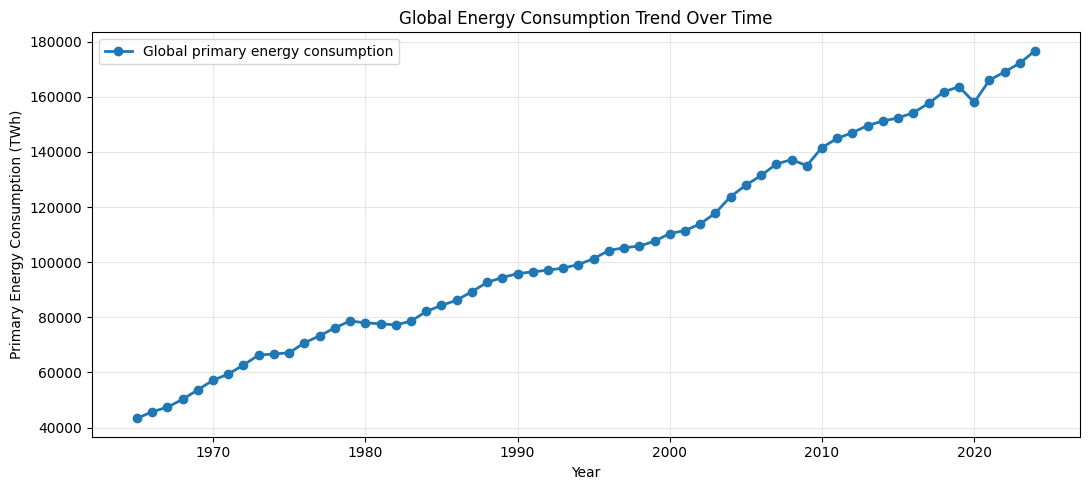

Interpretation: Global primary energy consumption increased from 43,360.31 TWh in 1965 to 176,737.09 TWh in 2024 (307.60% change).


In [61]:
# 1. LINE CHART: GLOBAL ENERGY CONSUMPTION TREND

print("\n1. GLOBAL ENERGY CONSUMPTION TREND")

if not viz_world.empty and "primary_energy_consumption" in viz_world.columns:
    world_trend = (
        viz_world[["year", "primary_energy_consumption"]]
        .dropna()
        .sort_values("year")
        .drop_duplicates(subset="year")
    )

    plt.figure(figsize=(11, 5))
    plt.plot(
        world_trend["year"],
        world_trend["primary_energy_consumption"],
        marker="o",
        linewidth=2,
        label="Global primary energy consumption"
    )
    plt.title("Global Energy Consumption Trend Over Time")
    plt.xlabel("Year")
    plt.ylabel("Primary Energy Consumption (TWh)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    first_value = world_trend.iloc[0]["primary_energy_consumption"]
    last_value = world_trend.iloc[-1]["primary_energy_consumption"]
    change_pct = ((last_value - first_value) / first_value * 100) if first_value else np.nan

    if last_value > first_value:
        trend_word = "increased"
    elif last_value < first_value:
        trend_word = "decreased"
    else:
        trend_word = "remained almost unchanged"

    print(
        f"Interpretation: Global primary energy consumption {trend_word} "
        f"from {first_value:,.2f} TWh in {int(world_trend.iloc[0]['year'])} "
        f"to {last_value:,.2f} TWh in {int(world_trend.iloc[-1]['year'])} "
        f"({change_pct:.2f}% change)."
    )
else:
    print("World-level data or primary_energy_consumption is not available.")


2. COUNTRY COMPARISON


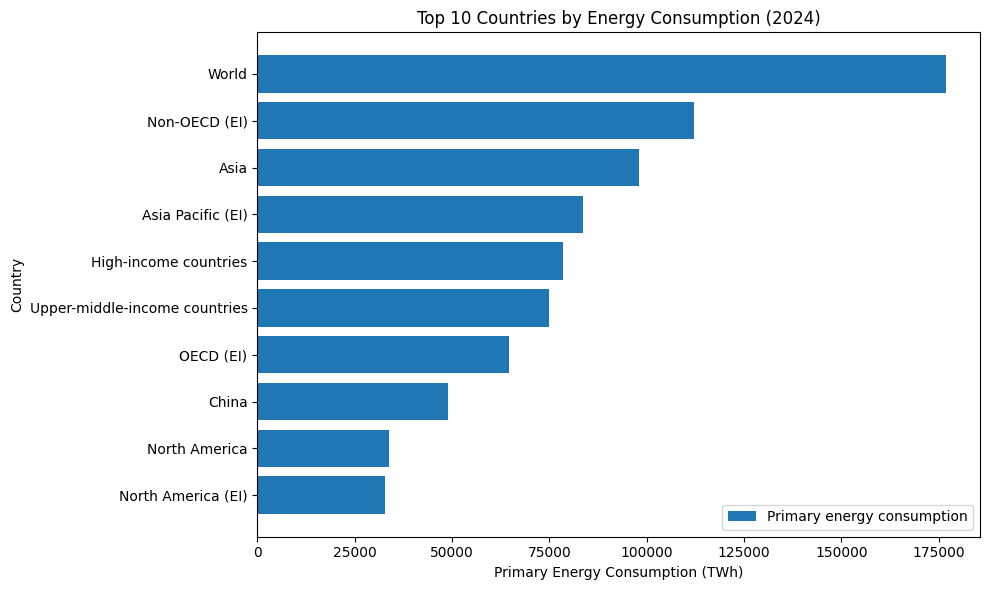

Interpretation: World has the highest primary energy consumption among the displayed top 10 countries.
Highest: 176737.09 TWh
Lowest: 32725.00 TWh


In [62]:
# 2. BAR CHART: COUNTRY COMPARISON
# ------------------------------------------------------------
print("\n2. COUNTRY COMPARISON")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Fallback definition of latest_country and latest_year if not present in the workspace
if "latest_country" not in globals() or "latest_year" not in globals():
    if "df_clean" in globals():
        viz_df = df_clean.copy()
    elif "df" in globals():
        viz_df = df.copy()
    else:
        viz_df = pd.DataFrame()

    if not viz_df.empty:
        viz_country = viz_df[viz_df["iso_code"].notna()].copy()
        latest_year = int(viz_country["year"].max())
        latest_country = viz_country[viz_country["year"] == latest_year].copy()
    else:
        latest_country = pd.DataFrame()
        latest_year = "Unknown"

if not latest_country.empty and "primary_energy_consumption" in latest_country.columns:
    top_countries = (
        latest_country[["country", "primary_energy_consumption"]]
        .dropna()
        .nlargest(10, "primary_energy_consumption")
        .sort_values("primary_energy_consumption")
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        top_countries["country"],
        top_countries["primary_energy_consumption"],
        label="Primary energy consumption"
    )
    plt.title(f"Top 10 Countries by Energy Consumption ({latest_year})")
    plt.xlabel("Primary Energy Consumption (TWh)")
    plt.ylabel("Country")
    plt.legend()
    plt.tight_layout()
    plt.show()

    if not top_countries.empty:
        highest = top_countries.tail(1).iloc[0]
        lowest = top_countries.head(1).iloc[0]
        highest_value = highest["primary_energy_consumption"]
        lowest_value = lowest["primary_energy_consumption"]

        print(
            f"Interpretation: {highest['country']} has the highest primary energy "
            f"consumption among the displayed top 10 countries."
        )
        print(f"Highest: {highest_value:.2f} TWh")
        print(f"Lowest: {lowest_value:.2f} TWh")
else:
    print("primary_energy_consumption is not available or data is empty.")

In [63]:
print(top_countries.shape)
print(top_countries.head(10))
print(top_countries.empty)

(10, 2)
                             country  primary_energy_consumption
14595             North America (EI)                32724.998047
14535                  North America                33782.062500
4575                           China                48987.101562
15127                      OECD (EI)                64689.937500
22100  Upper-middle-income countries                74834.484375
9218           High-income countries                78513.921875
1431               Asia Pacific (EI)                83748.132812
1346                            Asia                97910.242188
14262                  Non-OECD (EI)               112047.164062
22844                          World               176737.093750
False



3. RENEWABLE VS FOSSIL-FUEL COMPARISON


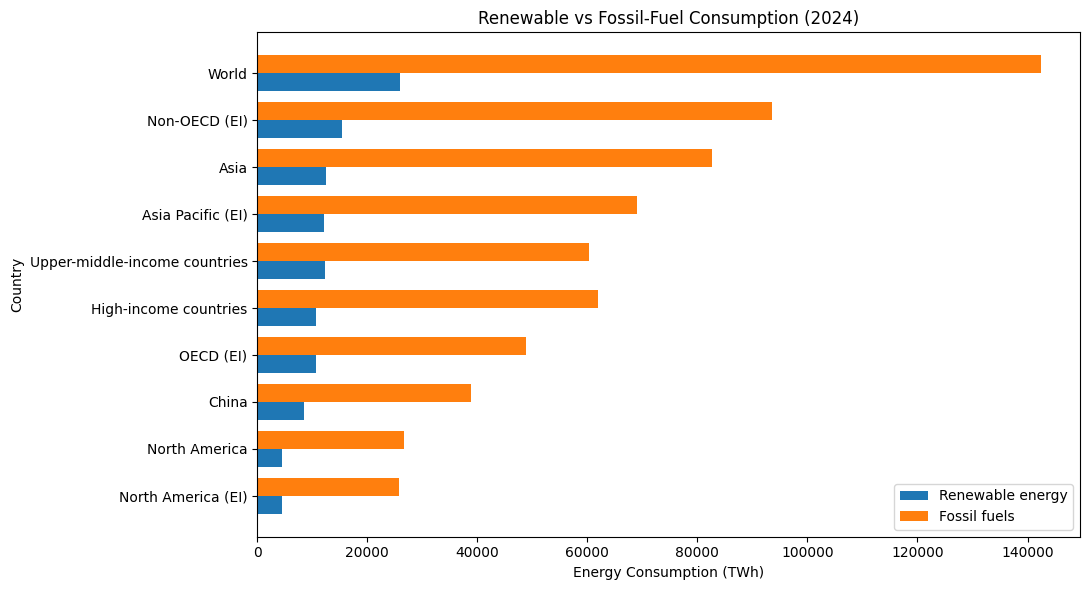

Interpretation: For the displayed 10 countries combined, Fossil-fuel consumption is higher. Renewable total = 116,980.45 TWh and fossil-fuel total = 650,244.21 TWh.


In [64]:
# 3. BAR CHART: RENEWABLE VS FOSSIL-FUEL COMPARISON

print("\n3. RENEWABLE VS FOSSIL-FUEL COMPARISON")

required_energy_cols = ["renewables_consumption", "fossil_fuel_consumption"]
if all(col in latest_country.columns for col in required_energy_cols):
    renewable_fossil = (
        latest_country[["country"] + required_energy_cols]
        .dropna()
        .copy()
    )

    # Select countries with the highest combined renewable and fossil consumption.
    renewable_fossil["combined_consumption"] = (
        renewable_fossil["renewables_consumption"]
        + renewable_fossil["fossil_fuel_consumption"]
    )
    renewable_fossil = renewable_fossil.nlargest(10, "combined_consumption")
    renewable_fossil = renewable_fossil.sort_values("combined_consumption")

    y = np.arange(len(renewable_fossil))
    bar_height = 0.38

    plt.figure(figsize=(11, 6))
    plt.barh(
        y - bar_height/2,
        renewable_fossil["renewables_consumption"],
        height=bar_height,
        label="Renewable energy"
    )
    plt.barh(
        y + bar_height/2,
        renewable_fossil["fossil_fuel_consumption"],
        height=bar_height,
        label="Fossil fuels"
    )
    plt.yticks(y, renewable_fossil["country"])
    plt.title(f"Renewable vs Fossil-Fuel Consumption ({latest_year})")
    plt.xlabel("Energy Consumption (TWh)")
    plt.ylabel("Country")
    plt.legend()
    plt.tight_layout()
    plt.show()

    total_renewable = renewable_fossil["renewables_consumption"].sum()
    total_fossil = renewable_fossil["fossil_fuel_consumption"].sum()
    if total_fossil > total_renewable:
        comparison_text = "Fossil-fuel consumption is higher"
    elif total_renewable > total_fossil:
        comparison_text = "Renewable consumption is higher"
    else:
        comparison_text = "Renewable and fossil-fuel consumption are equal"

    print(
        f"Interpretation: For the displayed 10 countries combined, "
        f"{comparison_text}. Renewable total = {total_renewable:,.2f} TWh "
        f"and fossil-fuel total = {total_fossil:,.2f} TWh."
    )
else:
    print("Renewable/fossil consumption columns are not available.")


4. CORRELATION HEATMAP


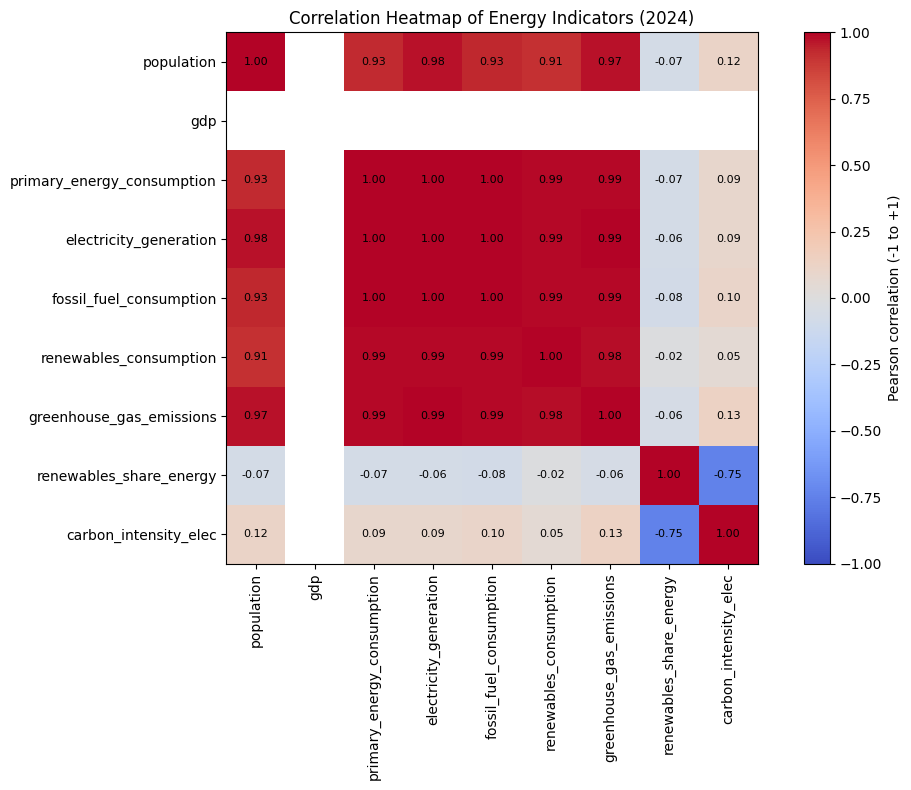

Interpretation: The strongest positive correlation is between primary_energy_consumption and fossil_fuel_consumption (r = 1.00).
The strongest negative correlation is between renewables_share_energy and carbon_intensity_elec (r = -0.75).
Remember: correlation indicates association; it does not prove causation.


In [65]:
# 4. HEATMAP: NUMERICAL CORRELATIONS

print("\n4. CORRELATION HEATMAP")

corr_columns = [
    "population",
    "gdp",
    "primary_energy_consumption",
    "electricity_generation",
    "fossil_fuel_consumption",
    "renewables_consumption",
    "greenhouse_gas_emissions",
    "renewables_share_energy",
    "carbon_intensity_elec"
]
corr_columns = [col for col in corr_columns if col in latest_country.columns]

if len(corr_columns) >= 2:
    corr_matrix = latest_country[corr_columns].corr(numeric_only=True)

    fig, ax = plt.subplots(figsize=(11, 8))
    image = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
    fig.colorbar(image, ax=ax, label="Pearson correlation (-1 to +1)")
    ax.set_xticks(range(len(corr_columns)))
    ax.set_yticks(range(len(corr_columns)))
    ax.set_xticklabels(corr_columns, rotation=90)
    ax.set_yticklabels(corr_columns)
    ax.set_title(f"Correlation Heatmap of Energy Indicators ({latest_year})")

    # Show correlation values inside the heatmap.
    for row in range(len(corr_columns)):
        for col in range(len(corr_columns)):
            value = corr_matrix.iloc[row, col]
            if pd.notna(value):
                ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()

    # Find the strongest positive and negative relationships, excluding self-correlation.
    upper_triangle = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    ).stack().dropna()

    if not upper_triangle.empty:
        strongest_positive_pair = upper_triangle.idxmax()
        strongest_negative_pair = upper_triangle.idxmin()
        print(
            "Interpretation: The strongest positive correlation is between "
            f"{strongest_positive_pair[0]} and {strongest_positive_pair[1]} "
            f"(r = {upper_triangle.max():.2f})."
        )
        print(
            "The strongest negative correlation is between "
            f"{strongest_negative_pair[0]} and {strongest_negative_pair[1]} "
            f"(r = {upper_triangle.min():.2f})."
        )
    print("Remember: correlation indicates association; it does not prove causation.")
else:
    print("Not enough numerical columns are available for a correlation heatmap.")


5. BOXPLOTS: DISTRIBUTIONS AND OUTLIERS


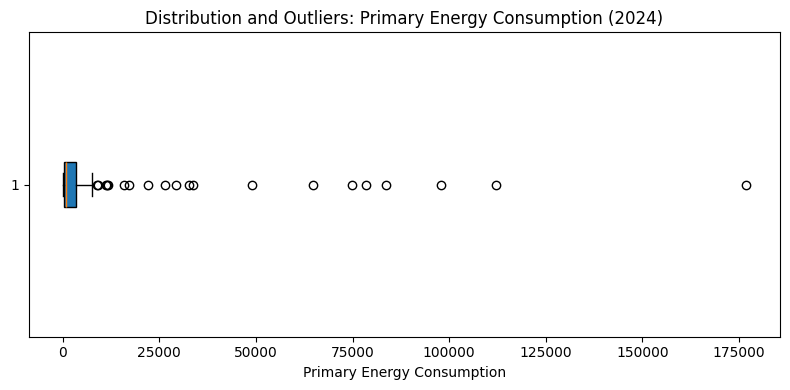

Interpretation (primary_energy_consumption): Median = 760.13; minimum = 29.57; maximum = 176,737.09; possible outliers = 20. Points beyond the whiskers are potential outliers, not automatically errors.


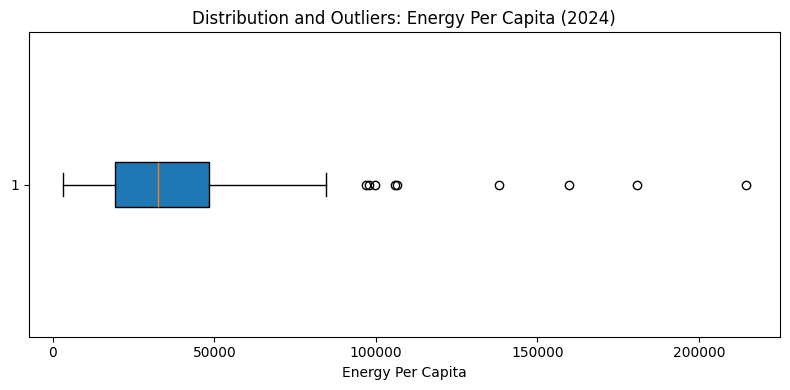

Interpretation (energy_per_capita): Median = 32,399.15; minimum = 3,048.31; maximum = 214,520.30; possible outliers = 9. Points beyond the whiskers are potential outliers, not automatically errors.


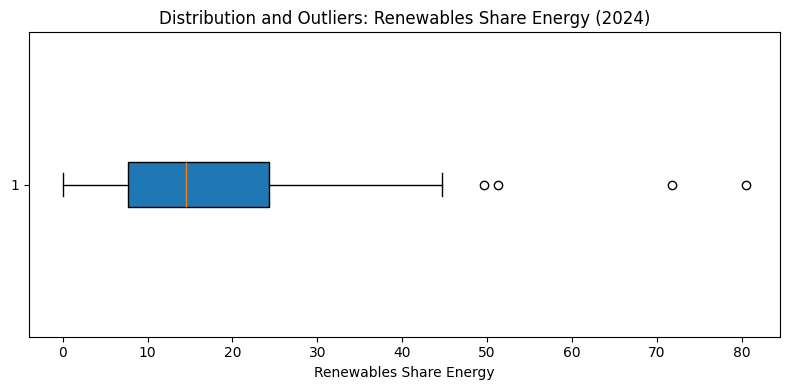

Interpretation (renewables_share_energy): Median = 14.51; minimum = 0.01; maximum = 80.50; possible outliers = 4. Points beyond the whiskers are potential outliers, not automatically errors.


In [66]:
# 5. BOXPLOTS: DISTRIBUTIONS AND OUTLIERS

print("\n5. BOXPLOTS: DISTRIBUTIONS AND OUTLIERS")

box_columns = [
    "primary_energy_consumption",
    "energy_per_capita",
    "renewables_share_energy"
]
box_columns = [col for col in box_columns if col in latest_country.columns]

for col in box_columns:
    values = latest_country[col].dropna()

    if len(values) > 0:
        plt.figure(figsize=(8, 4))
        plt.boxplot(values, vert=False, patch_artist=True)
        plt.title(f"Distribution and Outliers: {col.replace('_', ' ').title()} ({latest_year})")
        plt.xlabel(col.replace("_", " ").title())
        plt.tight_layout()
        plt.show()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        outlier_count = int(((values < lower_limit) | (values > upper_limit)).sum())

        print(
            f"Interpretation ({col}): Median = {values.median():,.2f}; "
            f"minimum = {values.min():,.2f}; maximum = {values.max():,.2f}; "
            f"possible outliers = {outlier_count}. "
            "Points beyond the whiskers are potential outliers, not automatically errors."
        )

5. Advanced Investigation & Findings

1. ADDITIONAL DATA ANALYSIS

Statistical Summary:


,year,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,biofuel_electricity,biofuel_share_elec,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
count,23232.000000,1.876000e+04,1.178000e+04,2070.000000,7903.000000,6338.000000,8057.000000,5796.000000,6107.000000,6082.000000,...,7640.000000,6379.000000,2798.000000,6293.000000,6405.000000,8237.000000,9328.000000,5145.000000,7483.000000,6379.000000
mean,1975.937543,1.057591e+08,4.257565e+11,43.478821,1.054261,55.157109,15.092053,71.064594,12.190516,1.962601,...,0.970065,0.219811,290.408295,6.021235,48.691258,68.159535,19.811565,214.958708,1.655012,0.518142
std,35.234386,4.697550e+08,3.507870e+12,286.672304,6.641947,180.660547,75.942537,202.044886,51.641143,5.356649,...,2.961908,0.766123,6070.498588,34.260035,281.755752,275.338843,117.845094,733.879417,4.909755,1.722173
min,1900.000000,1.776000e+03,1.642060e+08,-100.000000,-59.083984,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-100.000000,-46.534790,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1949.000000,1.600333e+06,1.426394e+10,-0.968287,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,2.328556,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1985.000000,6.950666e+06,4.357680e+10,6.695433,0.000000,0.000000,0.000000,0.874193,0.020000,0.153357,...,0.000000,0.000000,18.349456,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2005.000000,2.575218e+07,1.830576e+11,23.320313,0.000000,0.506788,0.061667,44.114410,0.920000,1.607833,...,0.214934,0.005892,45.211092,0.095950,0.915601,1.854649,0.120000,25.914005,0.564788,0.074523
max,2025.000000,8.161973e+09,1.301126e+14,6373.061523,144.289948,2587.707520,1366.878296,2450.790527,704.809998,77.586205,...,50.000000,9.881398,242384.859375,642.616699,6124.465332,3947.840332,2505.350098,9315.287109,58.357021,26.085308



Correlation Matrix:


,year,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,biofuel_electricity,biofuel_share_elec,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
year,1.000000,0.039569,0.079964,-0.011521,0.134081,0.337584,0.199725,0.119193,0.119993,0.126091,...,0.399298,0.420156,-0.043468,0.218600,0.231145,0.245620,0.173793,0.371879,0.324264,0.390011
population,0.039569,1.000000,0.910450,-0.047422,0.455681,0.006851,0.555410,-0.013404,0.780812,-0.017728,...,-0.004381,0.033285,-0.008482,0.551208,0.511266,-0.007480,0.512313,-0.023345,0.009517,0.007619
gdp,0.079964,0.910450,1.000000,-0.031852,0.568066,0.098747,0.899678,0.017627,0.977761,-0.001757,...,0.049554,0.114259,0.016902,0.880545,0.908578,0.063373,0.905262,0.054522,0.056077,0.070807
biofuel_cons_change_pct,-0.011521,-0.047422,-0.031852,1.000000,-0.012939,-0.069560,-0.050152,0.037635,-0.050627,-0.016136,...,-0.077695,-0.067200,-0.003854,-0.037004,-0.039550,-0.054803,-0.043834,-0.053725,-0.052190,-0.045578
biofuel_cons_change_twh,0.134081,0.455681,0.568066,-0.012939,1.000000,0.205616,0.658597,0.012704,0.626927,0.022879,...,0.051490,0.085780,-0.011155,0.498793,0.514322,0.058618,0.506436,0.063320,0.056831,0.084136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
wind_elec_per_capita,0.245620,-0.007480,0.063373,-0.054803,0.058618,0.572064,0.147905,0.493000,0.123067,0.209735,...,0.247108,0.442145,-0.020579,0.129801,0.176432,1.000000,0.160619,0.999202,0.840701,0.933117
wind_electricity,0.173793,0.512313,0.905262,-0.043834,0.506436,0.178889,0.846520,0.064146,0.921878,0.024777,...,0.162007,0.285313,-0.012209,0.899615,0.999878,0.160619,1.000000,0.175124,0.202372,0.232726
wind_energy_per_capita,0.371879,-0.023345,0.054522,-0.053725,0.063320,0.569806,0.154026,0.494589,0.097304,0.490657,...,0.418271,0.433090,-0.020824,0.133313,0.182261,0.999202,0.175124,1.000000,0.848770,0.933924
wind_share_elec,0.324264,0.009517,0.056077,-0.052190,0.056831,0.514179,0.150723,0.396830,0.146704,0.273243,...,0.357261,0.498975,-0.022506,0.142181,0.191720,0.840701,0.202372,0.848770,1.000000,0.941213


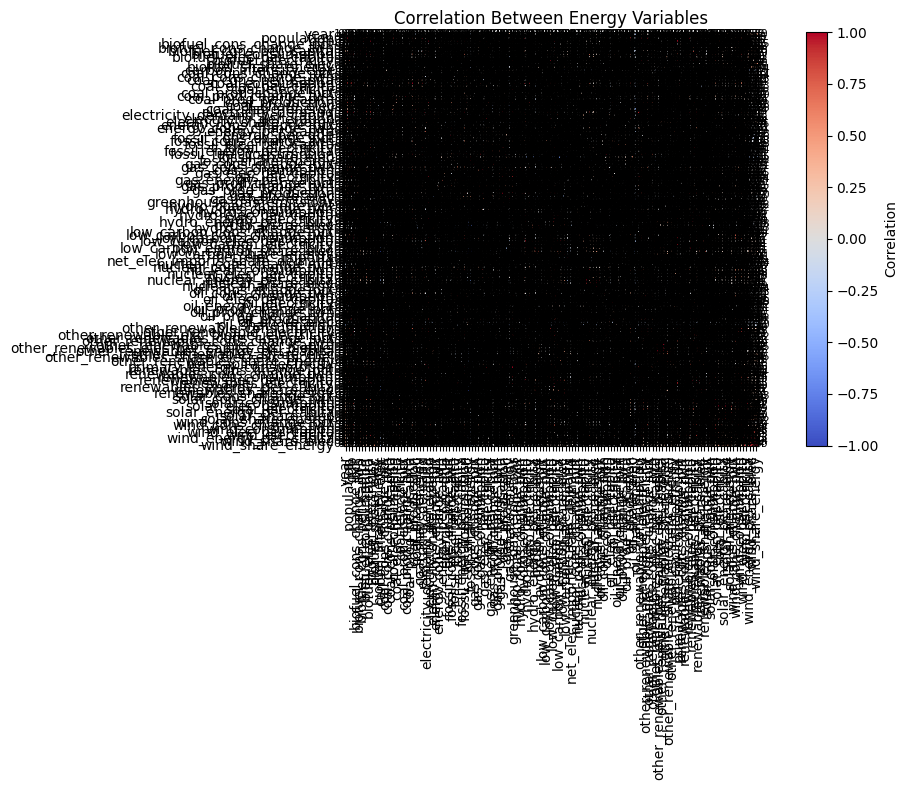


2. COUNTRY / REGION COMPARISON OVER TIME


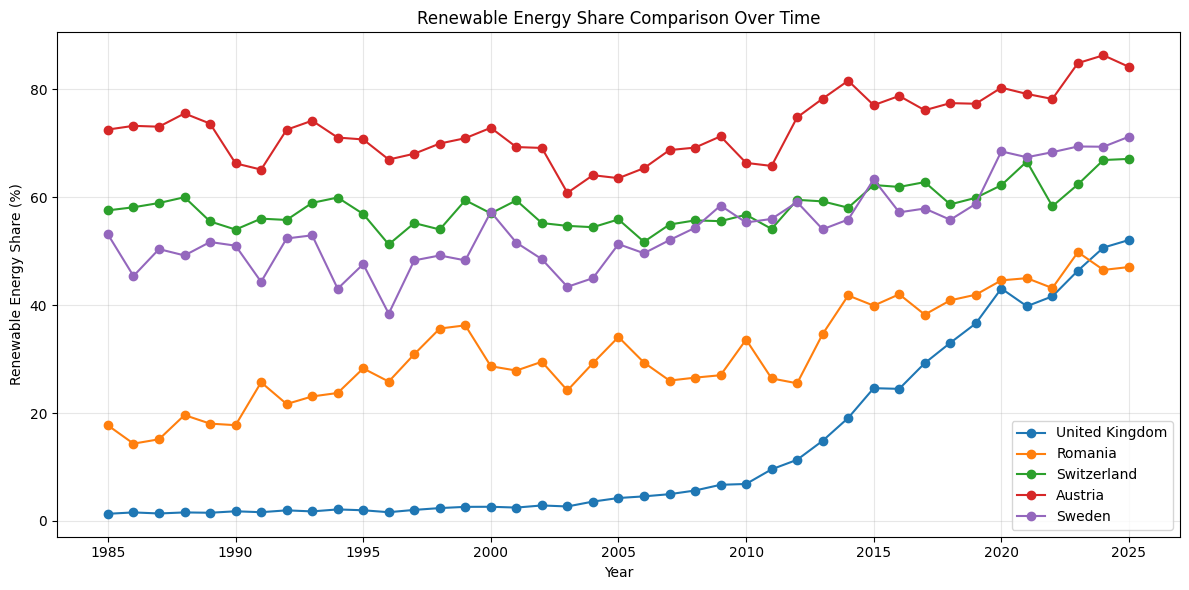


3. RENEWABLE ENERGY ADOPTION PATTERNS

Average Renewable Energy by Source:


,0
hydro_electricity,121.459649
wind_electricity,19.811565
biofuel_electricity,12.190516
solar_electricity,9.275418


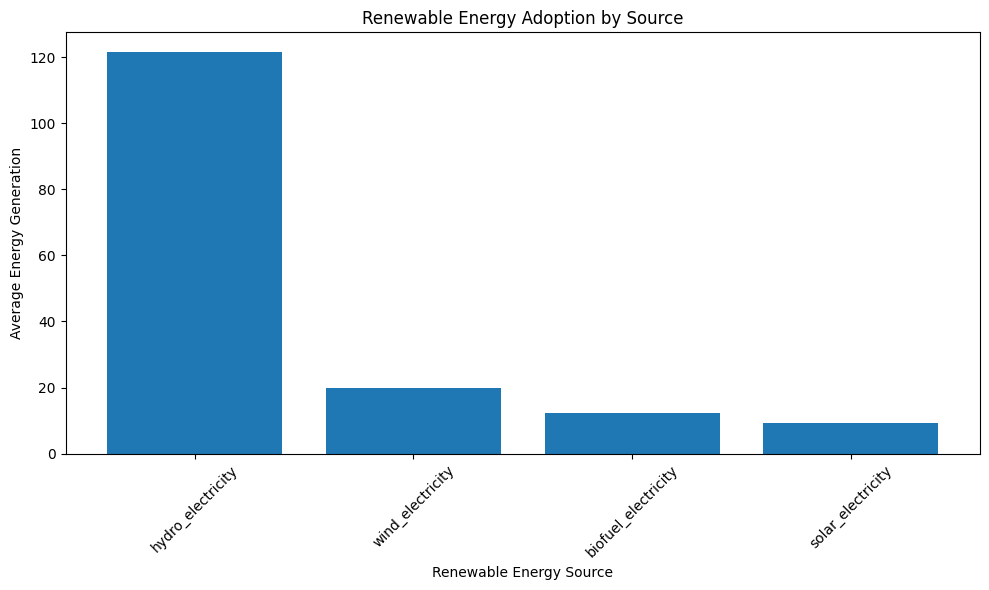


4. RENEWABLE ENERGY SHARE AND GROWTH

Renewable Energy Share:


,renewable_share
count,7646.000000
mean,29.786536
std,30.545185
min,0.000000
25%,3.513810
50%,18.499983
75%,50.000000
max,100.000000


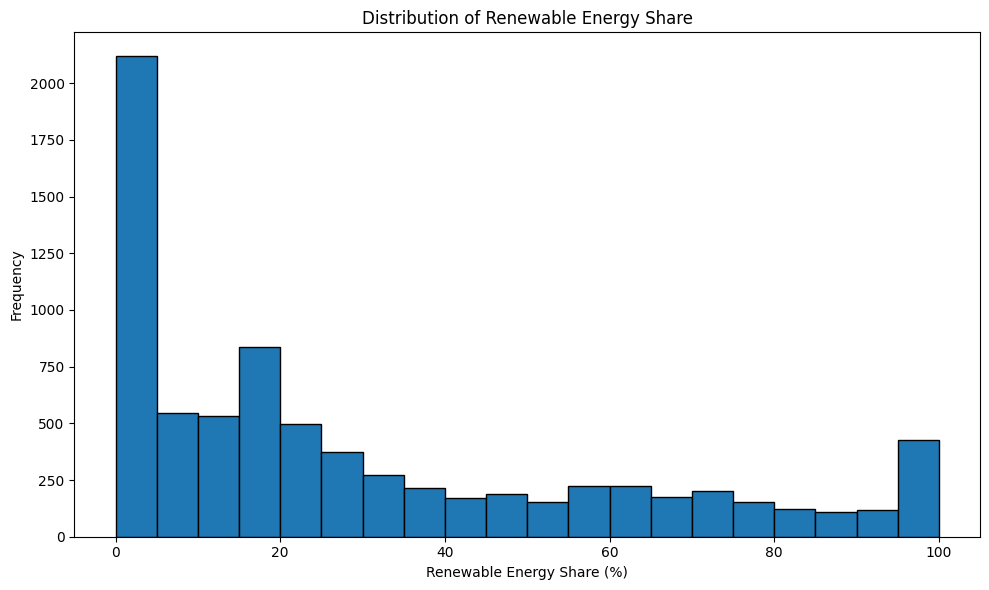


Yearly Renewable Energy Growth:


,Renewable_Energy,Growth_Rate_Percent
year,,
1900,0.000000,NaN
1901,0.000000,NaN
1902,0.000000,NaN
1903,0.000000,NaN
1904,0.000000,NaN
...,...,...
2021,70345.665005,5.626722
2022,75264.135187,6.991860
2023,77247.681214,2.635447


/usr/local/lib/python3.13/dist-packages/matplotlib/transforms.py:2436: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


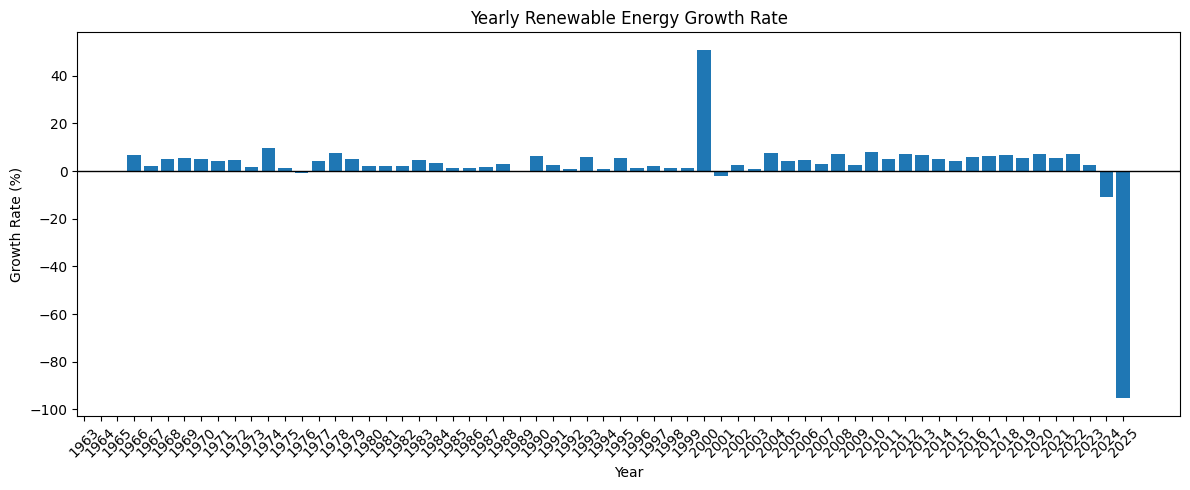


5. IMPORTANT ADDITIONAL PATTERNS

Top 10 Countries by Renewable Energy Share:


,renewables_share_elec
country,
Bhutan,100.000000
Lesotho,100.000000
Paraguay,99.999248
Iceland,99.947511
Nepal,99.722673
Democratic Republic of Congo,99.653317
Ethiopia,99.535742
Albania,98.907180
Norway,98.843589


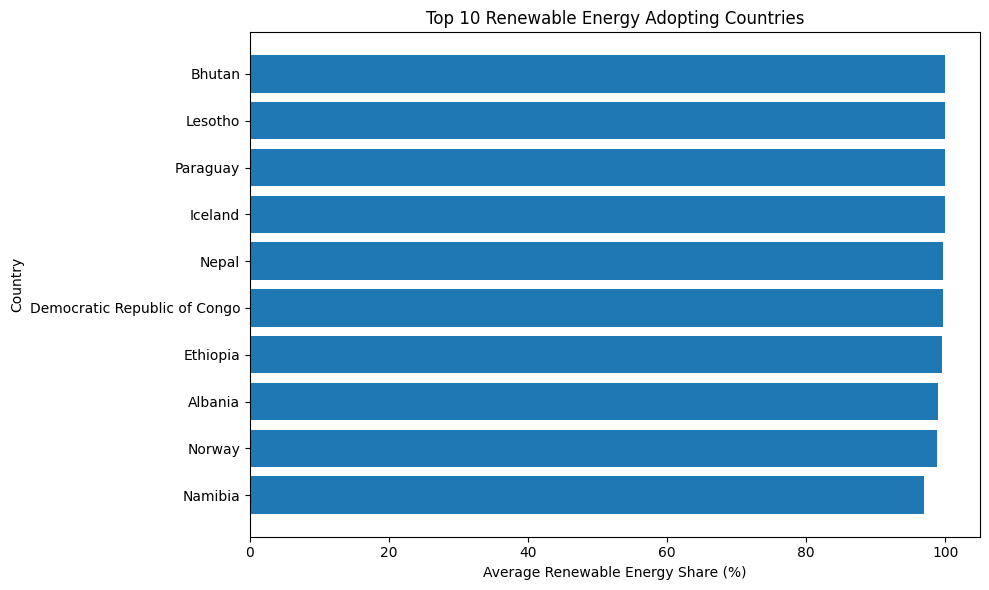


Leading Renewable Energy Source:
hydro_electricity

Missing Values:


,0
country,0
year,0
iso_code,6098
population,4472
gdp,11452
...,...
wind_electricity,13904
wind_energy_per_capita,18087
wind_share_elec,15749
wind_share_energy,16853



6. PRELIMINARY RESEARCH FINDINGS
1. Average renewable electricity generation is 162.25.
2. Average renewable electricity share is 29.79%.
3. The leading renewable energy source is hydro_electricity.
4. Bhutan has the highest average renewable energy share in the available data.

7. ANALYSIS LIMITATIONS

Missing Data Percentage:


,0
country,0.000000
year,0.000000
iso_code,26.248278
population,19.249311
gdp,49.294077
...,...
wind_electricity,59.848485
wind_energy_per_capita,77.853822
wind_share_elec,67.790117
wind_share_energy,72.542183



Duplicate Rows: 0

Dataset Shape: (23232, 131)
Available Year Range: 1900 - 2025
Number of Countries / Regions: 314

Potential Limitations:
- Missing values may affect analysis results.
- Different countries may use different reporting methods.
- Correlation does not establish causation.
- Available data may not represent every country equally.


In [67]:

# ============================================================
# ADDITIONAL RENEWABLE ENERGY DATA ANALYSIS
# Dataset is already loaded as df
# Libraries: Pandas, NumPy, Matplotlib
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. ADDITIONAL ANALYSIS RELATED TO RESEARCH QUESTIONS
# ============================================================

print("1. ADDITIONAL DATA ANALYSIS")

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Correlation analysis
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

print("\nCorrelation Matrix:")
display(correlation)

# Correlation heatmap using Matplotlib
plt.figure(figsize=(12, 8))

plt.imshow(correlation, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Correlation Between Energy Variables")
plt.tight_layout()
plt.show()


# ============================================================
# 2. COMPARE COUNTRIES OR REGIONS OVER TIME
# ============================================================

print("\n2. COUNTRY / REGION COMPARISON OVER TIME")

# Change these names according to your dataset
country_col = "country"
year_col = "year"
share_col = "renewables_share_elec"

if country_col in df.columns and year_col in df.columns:

    if share_col in df.columns:

        country_trend = df.groupby(
            [year_col, country_col]
        )[share_col].mean().reset_index()

        # Select five countries with the most records
        top_countries = (
            df[country_col]
            .value_counts()
            .head(5)
            .index
        )

        plt.figure(figsize=(12, 6))

        for country in top_countries:

            country_data = country_trend[
                country_trend[country_col] == country
            ]

            plt.plot(
                country_data[year_col],
                country_data[share_col],
                marker="o",
                label=country
            )

        plt.title("Renewable Energy Share Comparison Over Time")
        plt.xlabel("Year")
        plt.ylabel("Renewable Energy Share (%)")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    else:
        print("Renewable share column not found.")

else:
    print("Country or year column not found.")


# ============================================================
# 3. INVESTIGATE RENEWABLE ENERGY ADOPTION PATTERNS
# ============================================================

print("\n3. RENEWABLE ENERGY ADOPTION PATTERNS")

renewable_sources = [
    "solar_electricity",
    "wind_electricity",
    "hydro_electricity",
    "biofuel_electricity"
]

available_sources = [
    col for col in renewable_sources
    if col in df.columns
]

if available_sources:

    adoption = df[available_sources].mean().sort_values(
        ascending=False
    )

    print("\nAverage Renewable Energy by Source:")
    display(adoption)

    plt.figure(figsize=(10, 6))

    plt.bar(
        adoption.index,
        adoption.values
    )

    plt.title("Renewable Energy Adoption by Source")
    plt.xlabel("Renewable Energy Source")
    plt.ylabel("Average Energy Generation")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("No individual renewable energy source columns found.")


# ============================================================
# 4. CALCULATE RENEWABLE ENERGY SHARE AND GROWTH RATES
# ============================================================

print("\n4. RENEWABLE ENERGY SHARE AND GROWTH")

renewable_col = "renewables_electricity"
total_col = "electricity_generation"

# Calculate renewable share
if renewable_col in df.columns and total_col in df.columns:

    df["renewable_share"] = np.where(
        df[total_col] > 0,
        (df[renewable_col] / df[total_col]) * 100,
        np.nan
    )

    print("\nRenewable Energy Share:")
    display(df["renewable_share"].describe())

    plt.figure(figsize=(10, 6))

    plt.hist(
        df["renewable_share"].dropna(),
        bins=20,
        edgecolor="black"
    )

    plt.title("Distribution of Renewable Energy Share")
    plt.xlabel("Renewable Energy Share (%)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

elif share_col in df.columns:
    print("Existing renewable share column is available.")
    display(df[share_col].describe())

else:
    print("Required columns for renewable share are unavailable.")


# Yearly renewable energy growth rate

if renewable_col in df.columns and year_col in df.columns:

    yearly_energy = df.groupby(year_col)[
        renewable_col
    ].sum().sort_index()

    growth_rate = yearly_energy.pct_change() * 100

    growth_df = pd.DataFrame({
        "Renewable_Energy": yearly_energy,
        "Growth_Rate_Percent": growth_rate
    })

    print("\nYearly Renewable Energy Growth:")
    display(growth_df)

    plt.figure(figsize=(12, 5))

    plt.bar(
        growth_rate.index.astype(str),
        growth_rate.values
    )

    plt.axhline(0, color="black", linewidth=1)

    plt.title("Yearly Renewable Energy Growth Rate")
    plt.xlabel("Year")
    plt.ylabel("Growth Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("Renewable energy or year column unavailable.")


# ============================================================
# 5. IDENTIFY IMPORTANT PATTERNS NOT COVERED BY MEMBER 3
# ============================================================

print("\n5. IMPORTANT ADDITIONAL PATTERNS")

# Top 10 countries based on average renewable share

if country_col in df.columns and share_col in df.columns:

    country_ranking = df.groupby(country_col)[
        share_col
    ].mean().sort_values(ascending=False)

    print("\nTop 10 Countries by Renewable Energy Share:")
    display(country_ranking.head(10))

    plt.figure(figsize=(10, 6))

    top_10 = country_ranking.head(10).sort_values()

    plt.barh(
        top_10.index.astype(str),
        top_10.values
    )

    plt.title("Top 10 Renewable Energy Adopting Countries")
    plt.xlabel("Average Renewable Energy Share (%)")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()


# Identify the leading renewable energy source

if available_sources:

    print("\nLeading Renewable Energy Source:")
    print(adoption.idxmax())

# Missing values

print("\nMissing Values:")
display(df.isnull().sum())


# ============================================================
# 6. DEVELOP EVIDENCE-BASED PRELIMINARY FINDINGS
# ============================================================

print("\n6. PRELIMINARY RESEARCH FINDINGS")

findings = []

if renewable_col in df.columns:

    findings.append(
        f"Average renewable electricity generation is "
        f"{df[renewable_col].mean():.2f}."
    )

if share_col in df.columns:

    findings.append(
        f"Average renewable electricity share is "
        f"{df[share_col].mean():.2f}%."
    )

elif "renewable_share" in df.columns:

    findings.append(
        f"Average calculated renewable share is "
        f"{df['renewable_share'].mean():.2f}%."
    )

if available_sources:

    findings.append(
        f"The leading renewable energy source is "
        f"{adoption.idxmax()}."
    )

if country_col in df.columns and share_col in df.columns:

    best_country = country_ranking.idxmax()

    findings.append(
        f"{best_country} has the highest average renewable "
        f"energy share in the available data."
    )

if renewable_col in df.columns and year_col in df.columns:

    if len(yearly_energy) >= 2:

        first_value = yearly_energy.iloc[0]
        last_value = yearly_energy.iloc[-1]

        if first_value != 0:

            overall_growth = (
                (last_value - first_value) / abs(first_value)
            ) * 100

            findings.append(
                f"Renewable energy changed by "
                f"{overall_growth:.2f}% between "
                f"{yearly_energy.index[0]} and "
                f"{yearly_energy.index[-1]}."
            )

for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")


# ============================================================
# 7. INVESTIGATE LIMITATIONS OF THE ANALYSIS
# ============================================================

print("\n7. ANALYSIS LIMITATIONS")

# Missing data percentage
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("\nMissing Data Percentage:")
display(missing_percentage)

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Dataset information
print("\nDataset Shape:", df.shape)

if year_col in df.columns:
    print(
        "Available Year Range:",
        df[year_col].min(),
        "-",
        df[year_col].max()
    )

if country_col in df.columns:
    print(
        "Number of Countries / Regions:",
        df[country_col].nunique()
    )

print("\nPotential Limitations:")

if df.isnull().sum().sum() > 0:
    print("- Missing values may affect analysis results.")

if df.duplicated().sum() > 0:
    print("- Duplicate records may affect statistical calculations.")

if year_col not in df.columns:
    print("- Time-based comparison is not possible.")

if country_col not in df.columns:
    print("- Country or regional comparison is not possible.")

if renewable_col not in df.columns:
    print("- Renewable electricity generation data is unavailable.")

if total_col not in df.columns and share_col not in df.columns:
    print("- Renewable energy share cannot be calculated.")

print("- Different countries may use different reporting methods.")
print("- Correlation does not establish causation.")
print("- Available data may not represent every country equally.")



